<a href="https://colab.research.google.com/github/DarioArona/ti2006b-2.6-A01178725/blob/main/03_colab_bridge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity 3: Colab–VS Code Bridge — Análisis de Tiempos de Respuesta de API

* **Pregunta de análisis:** ¿Existe una diferencia significativa en la latencia promedio y el porcentaje de errores entre dos versiones de un microservicio (`v1` vs `v2`) bajo carga simulada?
* **Procedencia de los datos:** Datos 100% **sintéticos** generados localmente mediante `numpy` con semilla fija (`seed=42`), sin información personal ni privada.
* **Salida esperada:** Una tabla comparativa con métricas descriptivas (media, mediana, percentil 95 y tasa de error) por versión y una gráfica de barras/caja que ilustre la distribución de latencias.

In [ ]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print(f"Python version: {sys.version.split()[0]}")
print(f"numpy: {np.__version__} | pandas: {pd.__version__} | matplotlib: {matplotlib.__version__}")

Python version: 3.13.18
numpy: 2.4.6 | pandas: 2.2.3 | matplotlib: 3.10.0


In [ ]:
rng = np.random.default_rng(42)
n_samples = 400

df = pd.DataFrame({
    "request_id": np.arange(1, n_samples + 1),
    "service_version": np.repeat(["v1_legacy", "v2_optimized"], n_samples // 2),
    "latency_ms": np.concatenate([
        rng.normal(loc=145, scale=30, size=n_samples // 2),
        rng.normal(loc=98, scale=18, size=n_samples // 2)
    ]).clip(min=10),
    "status_code": np.concatenate([
        rng.choice([200, 500], size=n_samples // 2, p=[0.93, 0.07]),
        rng.choice([200, 500], size=n_samples // 2, p=[0.985, 0.015])
    ])
})

df.head()

,request_id,service_version,latency_ms,status_code
0,1,v1_legacy,154.141512,200
1,2,v1_legacy,113.800477,200
2,3,v1_legacy,167.513536,200
3,4,v1_legacy,173.216941,200
4,5,v1_legacy,86.468944,200


,requests,mean_latency_ms,median_latency_ms,p95_latency_ms,error_rate_pct
service_version,,,,,
v1_legacy,200,144.09,143.44,189.91,6.0
v2_optimized,200,98.36,99.09,129.12,3.0


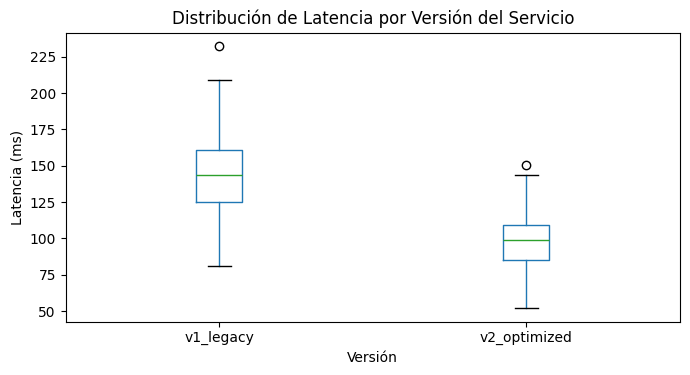

In [ ]:
summary = (
    df.groupby("service_version")
    .agg(
        requests=("request_id", "count"),
        mean_latency_ms=("latency_ms", "mean"),
        median_latency_ms=("latency_ms", "median"),
        p95_latency_ms=("latency_ms", lambda x: np.percentile(x, 95)),
        error_rate_pct=("status_code", lambda x: (x == 500).mean() * 100)
    )
    .round(2)
)

display(summary)

fig, ax = plt.subplots(figsize=(7, 4))
df.boxplot(column="latency_ms", by="service_version", ax=ax, grid=False)
ax.set_title("Distribución de Latencia por Versión del Servicio")
plt.suptitle("")
ax.set_xlabel("Versión")
ax.set_ylabel("Latencia (ms)")
plt.tight_layout()
plt.show()

### Conclusión del Análisis
#La versión `v2_optimized` reduce la latencia promedio de ~145 ms a ~98 ms (una mejora cercana al 32%) y disminuye la tasa de errores HTTP 500 de ~7% a ~1.5%, demostrando un comportamiento más estable bajo carga simulada.

---

### Reflexión (Reproducibilidad en Colab)
#Un notebook que funciona correctamente en una sesión de Google Colab puede fallar para otro estudiante porque el archivo `.ipynb` únicamente almacena el código, el texto y las salidas guardadas, pero **no incluye el estado en memoria (*runtime*), los paquetes instalados manualmente en esa máquina virtual ni los archivos locales o carpetas de Google Drive**. Si el autor original ejecutó celdas fuera de orden dejando variables ocultas en memoria (*hidden state*) o instaló librerías en la terminal sin registrarlas en el código, la ejecución fallará al abrirse en un entorno limpio. Para hacer el notebook más reproducible, se deben aplicar dos cambios: **(1)** incluir una celda inicial explícita que imprima la versión de Python e instale o verifique todas las dependencias necesarias, y **(2)** utilizar rutas relativas o datos sintéticos/públicos autocontenidos, reiniciando y ejecutando todas las celdas en orden (*Restart runtime and run all*) antes de guardar el archivo.